PV and Household Demand Integration

Project objective

This notebook combines hourly photovoltaic generation data from PVGIS for Nordhausen, Germany, with a modelled electricity demand profile for a three-person household.

The objective is to prepare a validated time-series dataset for subsequent battery simulation.

Main assumptions

- PV system reference capacity: 1 kWp
- Household size: 3 people
- Daily household electricity demand: 8 kWh
- Space heating: Central heating
- Domestic hot water: Centrally supplied
- Simulation period: 2022–2023

In [1]:
from pathlib import Path
import sys

# Locate the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "src").exists(), "Project root not found!"

# Make src modules accessible
sys.path.insert(0, str(PROJECT_ROOT / "src"))

print("Project root:", PROJECT_ROOT)
print("Source directory:", PROJECT_ROOT / "src")

Project root: /home/ablaze/projects/pv-battery-sizing-optimization
Source directory: /home/ablaze/projects/pv-battery-sizing-optimization/src


In [2]:
from pv_model import load_and_clean_pvgis_data
from demand_model import create_household_demand

from energy_balance import (
    validate_and_align_data,
    prepare_battery_simulation_inputs,
)

from battery_model import simulate_battery

In [3]:
import pandas as pd

PV_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "pvgis_clean.csv"

df_pv = pd.read_csv(
    PV_DATA_PATH,
    parse_dates=["time"],
    index_col="time"
)

print("PV data loaded successfully!")
print("Dataset shape:", df_pv.shape)
print("Date range:", df_pv.index.min(), "to", df_pv.index.max())

df_pv.head()

PV data loaded successfully!
Dataset shape: (17519, 6)
Date range: 2022-01-01 01:10:00 to 2023-12-31 23:10:00


,P,G(i),H_sun,T2m,WS10m,Int
time,,,,,,
2022-01-01 01:10:00,0.0,0.0,0.0,10.53,4.62,0.0
2022-01-01 02:10:00,0.0,0.0,0.0,10.45,4.48,0.0
2022-01-01 03:10:00,0.0,0.0,0.0,10.29,4.14,0.0
2022-01-01 04:10:00,0.0,0.0,0.0,10.16,4.00,0.0
2022-01-01 05:10:00,0.0,0.0,0.0,10.02,4.14,0.0


In [4]:
print("Missing values:")
display(df_pv.isna().sum())

print("\nDuplicate timestamps:")
print(df_pv.index.duplicated().sum())

print("\nChronological order:")
print(df_pv.index.is_monotonic_increasing)

print("\nTime interval distribution:")
display(
    df_pv.index.to_series()
    .diff()
    .value_counts()
)

Missing values:


P        0
G(i)     0
H_sun    0
T2m      0
WS10m    0
Int      0
dtype: int64


Duplicate timestamps:
0

Chronological order:
True

Time interval distribution:


time
0 days 01:00:00    17518
Name: count, dtype: int64

4. Household Electricity Demand

This section generates the electricity demand profile for a three-person household.

The baseline daily electricity consumption is assumed to be 8 kWh/day.

Space heating and domestic hot water are supplied centrally and are therefore excluded from the household electricity demand model.

In [5]:
DAILY_DEMAND_KWH = 8.0

df_demand = create_household_demand(
    timestamps=df_pv.index,
    daily_energy=DAILY_DEMAND_KWH
)

print("Household demand generated successfully!")
print("Dataset shape:", df_demand.shape)

display(df_demand.head())

Household demand generated successfully!
Dataset shape: (17519, 2)


,timestamp,demand_kWh
0,2022-01-01 01:10:00,0.117088
1,2022-01-01 02:10:00,0.117088
2,2022-01-01 03:10:00,0.117088
3,2022-01-01 04:10:00,0.147110
4,2022-01-01 05:10:00,0.244183


In [6]:
daily_demand = (
    df_demand
    .set_index("timestamp")["demand_kWh"]
    .resample("D")
    .sum()
)

print("Daily demand statistics:")
display(daily_demand.describe())

Daily demand statistics:


count    730.000000
mean       7.999798
std        0.005445
min        7.852890
25%        8.000000
50%        8.000000
75%        8.000000
max        8.000000
Name: demand_kWh, dtype: float64

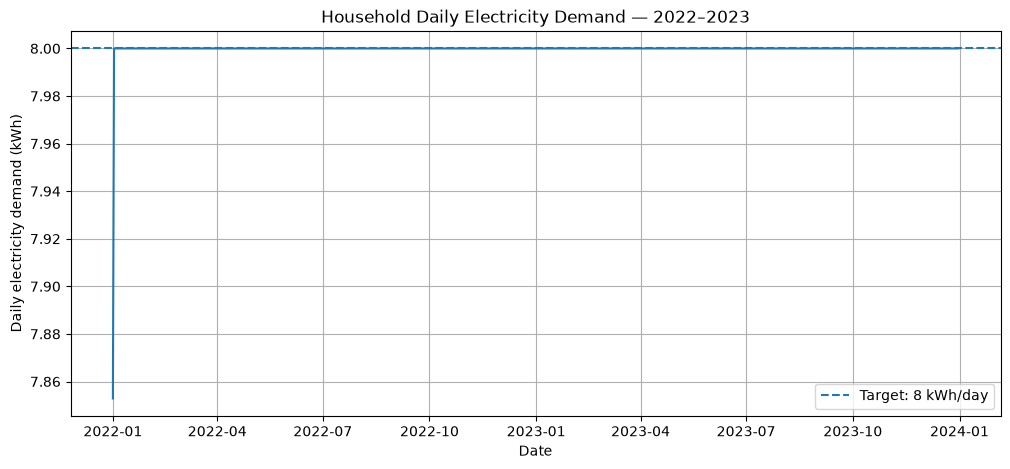

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(daily_demand.index, daily_demand.values)

plt.axhline(
    DAILY_DEMAND_KWH,
    linestyle="--",
    label="Target: 8 kWh/day"
)

plt.xlabel("Date")
plt.ylabel("Daily electricity demand (kWh)")
plt.title("Household Daily Electricity Demand — 2022–2023")
plt.legend()
plt.grid(True)
plt.show()

## 5. PV Generation and Household Demand Integration

This section combines the PV generation profile and household electricity demand.

The objective is to determine, for every time interval:
- PV energy generated
- Household energy consumed
- Energy surplus
- Energy deficit

In [8]:
df_model = validate_and_align_data(
    df_pv,
    df_demand
)

print("PV and demand successfully integrated!")
print("Dataset shape:", df_model.shape)

display(df_model.head())

✓ All timestamp, alignment, data type, and physical plausibility checks passed successfully.
PV and demand successfully integrated!
Dataset shape: (17519, 6)


,time_delta_hours,E_pv_kWh,E_demand_kWh,E_net_kWh,surplus_kWh,deficit_kWh
time,,,,,,
2022-01-01 01:10:00,1.0,0.0,0.117088,-0.117088,0.0,0.117088
2022-01-01 02:10:00,1.0,0.0,0.117088,-0.117088,0.0,0.117088
2022-01-01 03:10:00,1.0,0.0,0.117088,-0.117088,0.0,0.117088
2022-01-01 04:10:00,1.0,0.0,0.147110,-0.147110,0.0,0.147110
2022-01-01 05:10:00,1.0,0.0,0.244183,-0.244183,0.0,0.244183


## 6. Preparing Battery Simulation Inputs

The integrated PV and household demand dataset is converted into the input format required by the battery simulation model.

In [9]:
battery_inputs = prepare_battery_simulation_inputs(df_model)

print("Battery simulation inputs prepared!")
print("Number of intervals:", len(battery_inputs))

print("\nFirst simulation interval:")
print(battery_inputs[0])

Battery simulation inputs prepared!
Number of intervals: 17519

First simulation interval:
{'timestamp': Timestamp('2022-01-01 01:10:00'), 'pv_energy_kwh': np.float64(0.0), 'demand_energy_kwh': np.float64(0.11708781586189644), 'time_delta_hours': np.float64(1.0)}


In [12]:

battery_results = simulate_battery(
    intervals=battery_inputs,
    initial_stored_energy_kwh=2.5,
    battery_capacity_kwh=5.0,
    charge_efficiency=0.95,
    discharge_efficiency=0.95,
    min_soc=0.20,
    max_charge_power_kw=1.0,
    max_discharge_power_kw=1.0,
)

print("Battery simulation completed!")
print("Number of simulated intervals:", len(battery_results))

print("\nFirst simulation result:")
print(battery_results[0])


Battery simulation completed!
Number of simulated intervals: 17519

First simulation result:
{'timestamp': Timestamp('2022-01-01 01:10:00'), 'pv_energy_kwh': np.float64(0.0), 'demand_energy_kwh': np.float64(0.11708781586189644), 'time_delta_hours': np.float64(1.0), 'charge_input_kwh': 0.0, 'energy_stored_kwh': 0.0, 'new_stored_energy_kwh': np.float64(2.3767496675137934), 'remaining_surplus_kwh': 0.0, 'discharge_output_kwh': np.float64(0.11708781586189644), 'energy_removed_kwh': np.float64(0.12325033248620679), 'remaining_deficit_kwh': np.float64(0.0), 'new_soc': np.float64(47.53499335027587), 'grid_import_kwh': np.float64(0.0), 'grid_export_kwh': 0.0}


In [13]:
print("Number of results:", len(battery_results))

print("\nResult columns:")
print(battery_results[0].keys())

df_battery = pd.DataFrame(battery_results)

print("\nResults shape:", df_battery.shape)

display(df_battery.head())

Number of results: 17519

Result columns:
dict_keys(['timestamp', 'pv_energy_kwh', 'demand_energy_kwh', 'time_delta_hours', 'charge_input_kwh', 'energy_stored_kwh', 'new_stored_energy_kwh', 'remaining_surplus_kwh', 'discharge_output_kwh', 'energy_removed_kwh', 'remaining_deficit_kwh', 'new_soc', 'grid_import_kwh', 'grid_export_kwh'])

Results shape: (17519, 14)


,timestamp,pv_energy_kwh,demand_energy_kwh,time_delta_hours,charge_input_kwh,energy_stored_kwh,new_stored_energy_kwh,remaining_surplus_kwh,discharge_output_kwh,energy_removed_kwh,remaining_deficit_kwh,new_soc,grid_import_kwh,grid_export_kwh
0,2022-01-01 01:10:00,0.0,0.117088,1.0,0.0,0.0,2.376750,0.0,0.117088,0.123250,0.0,47.534993,0.0,0.0
1,2022-01-01 02:10:00,0.0,0.117088,1.0,0.0,0.0,2.253499,0.0,0.117088,0.123250,0.0,45.069987,0.0,0.0
2,2022-01-01 03:10:00,0.0,0.117088,1.0,0.0,0.0,2.130249,0.0,0.117088,0.123250,0.0,42.604980,0.0,0.0
3,2022-01-01 04:10:00,0.0,0.147110,1.0,0.0,0.0,1.975396,0.0,0.147110,0.154853,0.0,39.507920,0.0,0.0
4,2022-01-01 05:10:00,0.0,0.244183,1.0,0.0,0.0,1.718361,0.0,0.244183,0.257035,0.0,34.367223,0.0,0.0


## 7. Overall Battery and System Performance

This section evaluates the performance of the PV-battery system using the complete simulation results.

In [15]:

initial_stored_energy = 2.5

performance_summary = {
    "Total PV generation (kWh)": df_battery["pv_energy_kwh"].sum(),
    "Total household demand (kWh)": df_battery["demand_energy_kwh"].sum(),
    "Total battery charging input (kWh)": df_battery["charge_input_kwh"].sum(),
    "Total energy stored (kWh)": df_battery["energy_stored_kwh"].sum(),
    "Total battery discharge (kWh)": df_battery["discharge_output_kwh"].sum(),
    "Total energy removed (kWh)": df_battery["energy_removed_kwh"].sum(),
    "Total grid import (kWh)": df_battery["grid_import_kwh"].sum(),
    "Total grid export (kWh)": df_battery["grid_export_kwh"].sum(),
    "Final stored energy (kWh)": df_battery["new_stored_energy_kwh"].iloc[-1],
}

performance_summary = pd.Series(performance_summary)

display(performance_summary)


Total PV generation (kWh)             2182.444880
Total household demand (kWh)          5839.852890
Total battery charging input (kWh)     878.689113
Total energy stored (kWh)              834.754657
Total battery discharge (kWh)          794.441924
Total energy removed (kWh)             836.254657
Total grid import (kWh)               3741.655198
Total grid export (kWh)                  0.000000
Final stored energy (kWh)                1.000000
dtype: float64

In [16]:
print("PV surplus before battery charging:")
print(df_model["surplus_kWh"].sum(), "kWh")

print("\nBattery charging input:")
print(df_battery["charge_input_kwh"].sum(), "kWh")

print("\nRemaining surplus after battery charging:")
print(df_battery["remaining_surplus_kwh"].sum(), "kWh")

print("\nGrid export:")
print(df_battery["grid_export_kwh"].sum(), "kWh")

print("\nNumber of intervals with PV surplus:")
print((df_model["surplus_kWh"] > 0).sum())

print("\nNumber of intervals with remaining surplus:")
print((df_battery["remaining_surplus_kwh"] > 0).sum())

print("\nMaximum PV surplus in one interval:")
print(df_model["surplus_kWh"].max(), "kWh")

PV surplus before battery charging:
878.6891128021014 kWh

Battery charging input:
878.6891128021014 kWh

Remaining surplus after battery charging:
0.0 kWh

Grid export:
0.0 kWh

Number of intervals with PV surplus:
3132

Number of intervals with remaining surplus:
0

Maximum PV surplus in one interval:
0.6878086289717288 kWh


In [17]:
total_pv = df_battery["pv_energy_kwh"].sum()
total_demand = df_battery["demand_energy_kwh"].sum()

total_grid_import = df_battery["grid_import_kwh"].sum()
total_grid_export = df_battery["grid_export_kwh"].sum()

pv_self_consumption = (
    (total_pv - total_grid_export) / total_pv
) * 100

household_self_sufficiency = (
    (total_demand - total_grid_import) / total_demand
) * 100

charging_losses = (
    df_battery["charge_input_kwh"].sum()
    - df_battery["energy_stored_kwh"].sum()
)

discharging_losses = (
    df_battery["energy_removed_kwh"].sum()
    - df_battery["discharge_output_kwh"].sum()
)

print(f"PV self-consumption: {pv_self_consumption:.2f}%")
print(f"Household self-sufficiency: {household_self_sufficiency:.2f}%")
print(f"Charging losses: {charging_losses:.3f} kWh")
print(f"Discharging losses: {discharging_losses:.3f} kWh")
print(f"Total battery losses: {charging_losses + discharging_losses:.3f} kWh")

PV self-consumption: 100.00%
Household self-sufficiency: 35.93%
Charging losses: 43.934 kWh
Discharging losses: 41.813 kWh
Total battery losses: 85.747 kWh


In [18]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from system_simulation import run_system_simulation

print("Project root:", PROJECT_ROOT)
print("Import successful!")

Project root: /home/ablaze/projects/pv-battery-sizing-optimization
Import successful!


In [19]:
pv_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "pvgis_clean.csv"
)

results = run_system_simulation(
    pv_data_path=pv_path
)

print("Number of intervals:", len(results.df_battery))

print("\nSimulation summary:")
for key, value in results.summary.items():
    print(f"{key}: {value:.4f}")

✓ All timestamp, alignment, data type, and physical plausibility checks passed successfully.
Number of intervals: 17519

Simulation summary:
total_pv_kwh: 2182.4449
total_demand_kwh: 5839.8529
charge_input_kwh: 878.6891
energy_stored_kwh: 834.7547
discharge_output_kwh: 794.4419
energy_removed_kwh: 836.2547
grid_import_kwh: 3741.6552
grid_export_kwh: 0.0000
initial_stored_energy_kwh: 2.5000
final_stored_energy_kwh: 1.0000
charge_losses_kwh: 43.9345
discharge_losses_kwh: 41.8127
total_battery_losses_kwh: 85.7472
pv_self_consumption_pct: 100.0000
household_self_sufficiency_pct: 35.9289
